In [1]:
#!pip install grape
from grape import Graph

In [2]:
import numpy as np
import pandas as pd
import pickle

## Notebook to create edge prediction pipeline with NP-KG (v2.1) and evaluate embeddings

In [3]:
KG_PATH = '../../np-kg/resources/knowledge_graphs/'
DIR_PATH = 'grape-embeddings/'

In [7]:
npkg_default = Graph.from_csv(
    node_path=KG_PATH+'nodeTypes_CURIE_v2.0.0.tsv',
    node_list_node_types_column_number=1,
    nodes_column_number=0,
    node_list_separator='\t',
    node_list_header=True,
    edge_path=KG_PATH+'NP-KG_BETWEENNESS-WEIGHTED-PK-CURIE_v2.0.0.tsv',
    edge_list_separator='\t',
    edge_list_header=True,
    edge_list_edge_types_column_number=1,
    sources_column_number=0,
    destinations_column_number=2,
    weights_column_number=3,
    directed=True,
    verbose=True
)

In [4]:
npkg_hashed = Graph.from_csv(
    node_path=KG_PATH+'nodeTypes_CURIE_v2.0.0.tsv',
    node_list_node_types_column_number=1,
    nodes_column_number=0,
    node_list_separator='\t',
    node_list_header=True,
    edge_path=KG_PATH+'NP-KG_BETWEENNESS-WEIGHTED-PK-CURIE-HASHED_v2.0.0.tsv',
    edge_list_separator='\t',
    edge_list_header=True,
    edge_list_edge_types_column_number=1,
    sources_column_number=0,
    destinations_column_number=2,
    weights_column_number=3,
    directed=True,
    verbose=True
)

In [8]:
#(number of components, number of nodes of the smallest component, number of nodes of the biggest component)
npkg_default.get_number_of_connected_components()

(347, 1, 1090124)

In [5]:
npkg_hashed.get_number_of_connected_components()

(347, 1, 1090124)

In [9]:
npkg_default = npkg_default.remove_disconnected_nodes()

In [6]:
npkg_hashed = npkg_hashed.remove_disconnected_nodes()

In [10]:
npkg_default.get_number_of_connected_components()

(1, 1090124, 1090124)

In [7]:
npkg_hashed.get_number_of_connected_components()

(1, 1090124, 1090124)

In [8]:
npkg_hashed.enable()

## Split into train and test

In [12]:
train_default, test_default = npkg_default.connected_holdout(
    train_size = 0.8,
    random_state=42,
    include_all_edge_types=True,
    #edge_types = [optional list of strings if restricting holdout/evaluation to specific edge types]
    verbose=True
)

In [9]:
train_hashed, test_hashed = npkg_hashed.connected_holdout(
    train_size = 0.8,
    random_state=42,
    include_all_edge_types=True,
    #edge_types = [optional list of strings if restricting holdout/evaluation to specific edge types]
    verbose=True
)

In [13]:
print('Train holdout:')
print('Number of edges: ', train_default.get_number_of_edges())
print('Number of nodes: ', train_default.get_number_of_nodes())
print('Edge types: ', train_default.get_number_of_edge_types())

Train holdout:
Number of edges:  6338029
Number of nodes:  1090124
Edge types:  355


In [14]:
print('Test holdout:')
print('Number of edges: ', test_default.get_number_of_edges())
print('Number of nodes: ', test_default.get_number_of_nodes())
print('Edge types: ', test_default.get_number_of_edge_types())

Test holdout:
Number of edges:  1584507
Number of nodes:  1090124
Edge types:  355


In [15]:
train_default.get_number_of_connected_components()

(1, 1090124, 1090124)

## Generate embeddings

### TransE

In [11]:
from grape.embedders import TransEEnsmallen

In [12]:
#Defaults: embedding_size=100, epochs=100, relu_bias=1.0, learning_rate=0.05, learning_rate_decay=0.9, random_state=42
#Time taken on CPU: 8 minutes, GPU: 4 minutes
transe_embed_model = TransEEnsmallen(
    embedding_size=100,
    epochs=100,
    random_state=42,
    verbose=True,
    enable_cache=True
)
transe_embedding = transe_embed_model.fit_transform(npkg_hashed)

In [14]:
transe_embedding_train = transe_embed_model.fit_transform(train_hashed)

In [13]:
##save embeddings (if no path provided above)
import pickle
transe_embedding_dict = transe_embedding.dump()
with open(DIR_PATH+'npkg_transE_embedding_dict_hashed.pickle', 'wb') as file_trans:
    pickle.dump(transe_embedding_dict, file_trans)

In [15]:
transe_embedding_train_dict = transe_embedding_train.dump()
with open(DIR_PATH+'npkg_transE_embedding_dict_train_hashed.pickle', 'wb') as file_trans:
    pickle.dump(transe_embedding_train_dict, file_trans)

In [16]:
##take a look at the node embedding
#index of dataframe are the node URIs from the graph
transe_embedding.get_node_embedding_from_index(0)

,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
cl:0000594,-0.076197,0.090269,-0.156259,0.077022,-0.113024,-0.096382,0.092141,0.069655,0.114401,-0.057494,...,-0.081338,-0.058055,-0.091574,0.123750,0.060570,0.118128,-0.108673,-0.133357,0.081595,-0.075910
chebi:151576,0.084500,0.105589,0.058938,-0.078626,-0.152424,-0.076111,0.137328,-0.104271,0.104795,-0.068977,...,-0.081910,0.107494,0.111123,-0.069347,-0.111406,0.094821,0.078107,-0.090788,0.087362,0.123190
mondo:0022220,0.075675,0.022172,0.104629,-0.104070,-0.111785,-0.105498,0.036975,-0.105361,0.010733,-0.060061,...,-0.067017,0.115847,0.120666,-0.311669,-0.081316,0.110046,0.297807,-0.071749,0.043412,0.039055
chebi:126939,0.112633,0.066471,0.051852,-0.120682,-0.098855,-0.066674,0.083067,-0.130570,0.083587,-0.036603,...,-0.035327,0.141838,0.120965,-0.071546,-0.136214,0.101031,0.107034,-0.091624,0.056535,0.131026
pr:p36603,0.095652,0.038129,-0.045655,-0.085230,-0.090897,-0.008429,0.009040,-0.030163,0.071396,-0.024679,...,0.043348,0.117577,0.099797,0.021185,-0.113911,0.133686,-0.005814,-0.096933,0.051628,0.088132
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
pr:o34798,0.089759,0.072803,0.053656,0.020037,-0.113480,-0.027379,0.077084,-0.072474,0.049011,-0.049533,...,-0.116971,0.100680,0.146567,-0.060130,-0.106605,0.109996,0.081159,-0.052332,0.061025,0.116445
pr:p26748,-0.073420,-0.087676,-0.085615,-0.018547,0.051254,0.095809,-0.099840,0.071721,-0.088003,0.126965,...,0.247956,-0.062306,-0.087611,0.090066,0.040220,-0.073474,-0.086810,0.060300,-0.095909,-0.068016
pr:p80403,-0.019630,-0.064205,-0.097716,0.000861,0.047193,0.017684,-0.059639,0.010289,-0.037764,0.093928,...,0.110940,-0.014616,-0.027594,0.103336,-0.008093,-0.031353,-0.061358,-0.002404,-0.052948,-0.002720
pr:q8vqf4,0.113902,-0.078607,-0.069443,-0.129598,-0.087902,-0.115141,0.084851,-0.119015,0.094272,-0.090936,...,-0.116825,0.124831,0.117072,0.042895,-0.113322,0.091659,0.084207,-0.108048,0.088304,0.101954


In [17]:
##take a look at the edge embedding (generated for the 4 different edge types in the graph)
transe_embedding.get_edge_type_embedding_from_index(0)

,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
ro:0001015,9.343759,-8.821261,7.925818,-9.210183,5.124503,8.235906,-7.549575,-7.976781,-6.025126,8.397343,...,7.979005,8.302781,7.701551,-8.068160,-8.455068,-6.162811,7.689701,6.918274,-7.541580,9.262009
ro:0001025,-8.066725,10.012826,-7.002256,8.090478,-6.161886,-9.208684,8.514880,6.776635,6.414416,-9.566317,...,-8.418158,-6.890661,-6.309775,6.990983,7.278259,7.445856,-6.567382,-7.438264,8.042902,-8.828130
rdfs:subClassOf,-4.742191,-4.768744,-4.568683,4.779795,4.493669,5.501620,-5.252505,4.277182,-4.693223,5.258232,...,4.019984,-4.606397,-4.238197,4.598176,4.496351,-4.782948,-4.651922,5.064382,-5.107773,-4.590147
bfo:0000050,3.098311,4.262894,3.384670,-3.079026,-3.202020,-4.139001,4.389296,-3.273744,3.717633,-4.550816,...,-4.343286,3.393273,-3.365220,-3.625510,-3.051233,3.373124,3.470990,-4.307695,4.410750,2.656678
ro:0002150,-0.155205,1.391772,1.271994,0.820029,-2.151255,-0.651799,0.909027,-0.941954,1.658322,-0.718519,...,-1.817500,-0.848891,-0.463236,-0.891880,-0.116444,0.560078,0.787485,-0.436359,1.160502,0.232975
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
bspo:0015009,-0.058295,-0.135416,-0.080495,-0.183230,0.130028,0.080229,0.212257,0.234967,0.248785,-0.236355,...,0.092815,0.174193,0.219345,-0.235075,-0.024856,-0.227781,0.205955,-0.118316,-0.009624,-0.143122
ro:0002509,-0.005287,-0.113945,0.005803,0.166636,0.083415,0.237745,-0.201473,-0.074135,-0.113019,0.099993,...,0.023686,-0.160749,0.079334,-0.083058,0.250888,0.198982,-0.112798,0.056145,0.072475,0.150727
so#transcribed:from,0.036271,0.023052,0.007623,0.235868,-0.035994,0.084781,-0.155684,0.224813,-0.078433,0.175234,...,0.039883,0.123727,-0.051611,0.312017,0.134615,0.096536,0.100877,0.001172,-0.089069,-0.207910
foodon:00001301,0.170626,-0.109640,0.040365,0.238884,-0.160550,0.155289,-0.251748,0.240150,0.157679,-0.082079,...,0.245149,-0.106366,-0.209371,0.117946,0.199597,-0.124703,0.037288,0.317942,-0.255023,-0.280817


## Load embeddings

In [20]:
from grape import EmbeddingResult

In [19]:
with open(DIR_PATH+'npkg_transE_embedding_dict_default.pickle', 'rb') as filep:
    transe_embedding_default_dict = pickle.load(filep)
transe_embedding_default = EmbeddingResult.load(transe_embedding_default_dict)

In [20]:
with open(DIR_PATH+'npkg_train_transE_embedding_default.pickle', 'rb') as fileptrain:
    transe_embedding_default_dict_train = pickle.load(fileptrain)
transe_embedding_default_train = EmbeddingResult.load(transe_embedding_default_dict_train)

In [21]:
with open(DIR_PATH+'npkg_transE_embedding_dict_hashed.pickle', 'rb') as filep:
    transe_embedding_hashed_dict = pickle.load(filep)
transe_embedding_hashed = EmbeddingResult.load(transe_embedding_hashed_dict)

In [22]:
with open(DIR_PATH+'npkg_transE_embedding_dict_train_hashed.pickle', 'rb') as fileptrain:
    transe_embedding_hashed_dict_train = pickle.load(fileptrain)
transe_embedding_hashed_train = EmbeddingResult.load(transe_embedding_hashed_dict_train)

## Visualization

In [23]:
from grape import GraphVisualizer
import matplotlib.pyplot as plt

Edge embedding methods: hadamard, concatenate, average, sum

In [24]:
%%time
vis_had = GraphVisualizer(npkg_hashed, 
                          verbose=True, 
                          edge_embedding_methods="Hadamard", 
                          rotate=False)

CPU times: user 8.1 s, sys: 1.48 s, total: 9.57 s
Wall time: 3.79 s


[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 20000 samples in 0.001s...
[t-SNE] Computed neighbors for 20000 samples in 0.445s...
[t-SNE] Computed conditional probabilities for sample 1000 / 20000
[t-SNE] Computed conditional probabilities for sample 2000 / 20000
[t-SNE] Computed conditional probabilities for sample 3000 / 20000
[t-SNE] Computed conditional probabilities for sample 4000 / 20000
[t-SNE] Computed conditional probabilities for sample 5000 / 20000
[t-SNE] Computed conditional probabilities for sample 6000 / 20000
[t-SNE] Computed conditional probabilities for sample 7000 / 20000
[t-SNE] Computed conditional probabilities for sample 8000 / 20000
[t-SNE] Computed conditional probabilities for sample 9000 / 20000
[t-SNE] Computed conditional probabilities for sample 10000 / 20000
[t-SNE] Computed conditional probabilities for sample 11000 / 20000
[t-SNE] Computed conditional probabilities for sample 12000 / 20000
[t-SNE] Computed conditional probabilities for sam

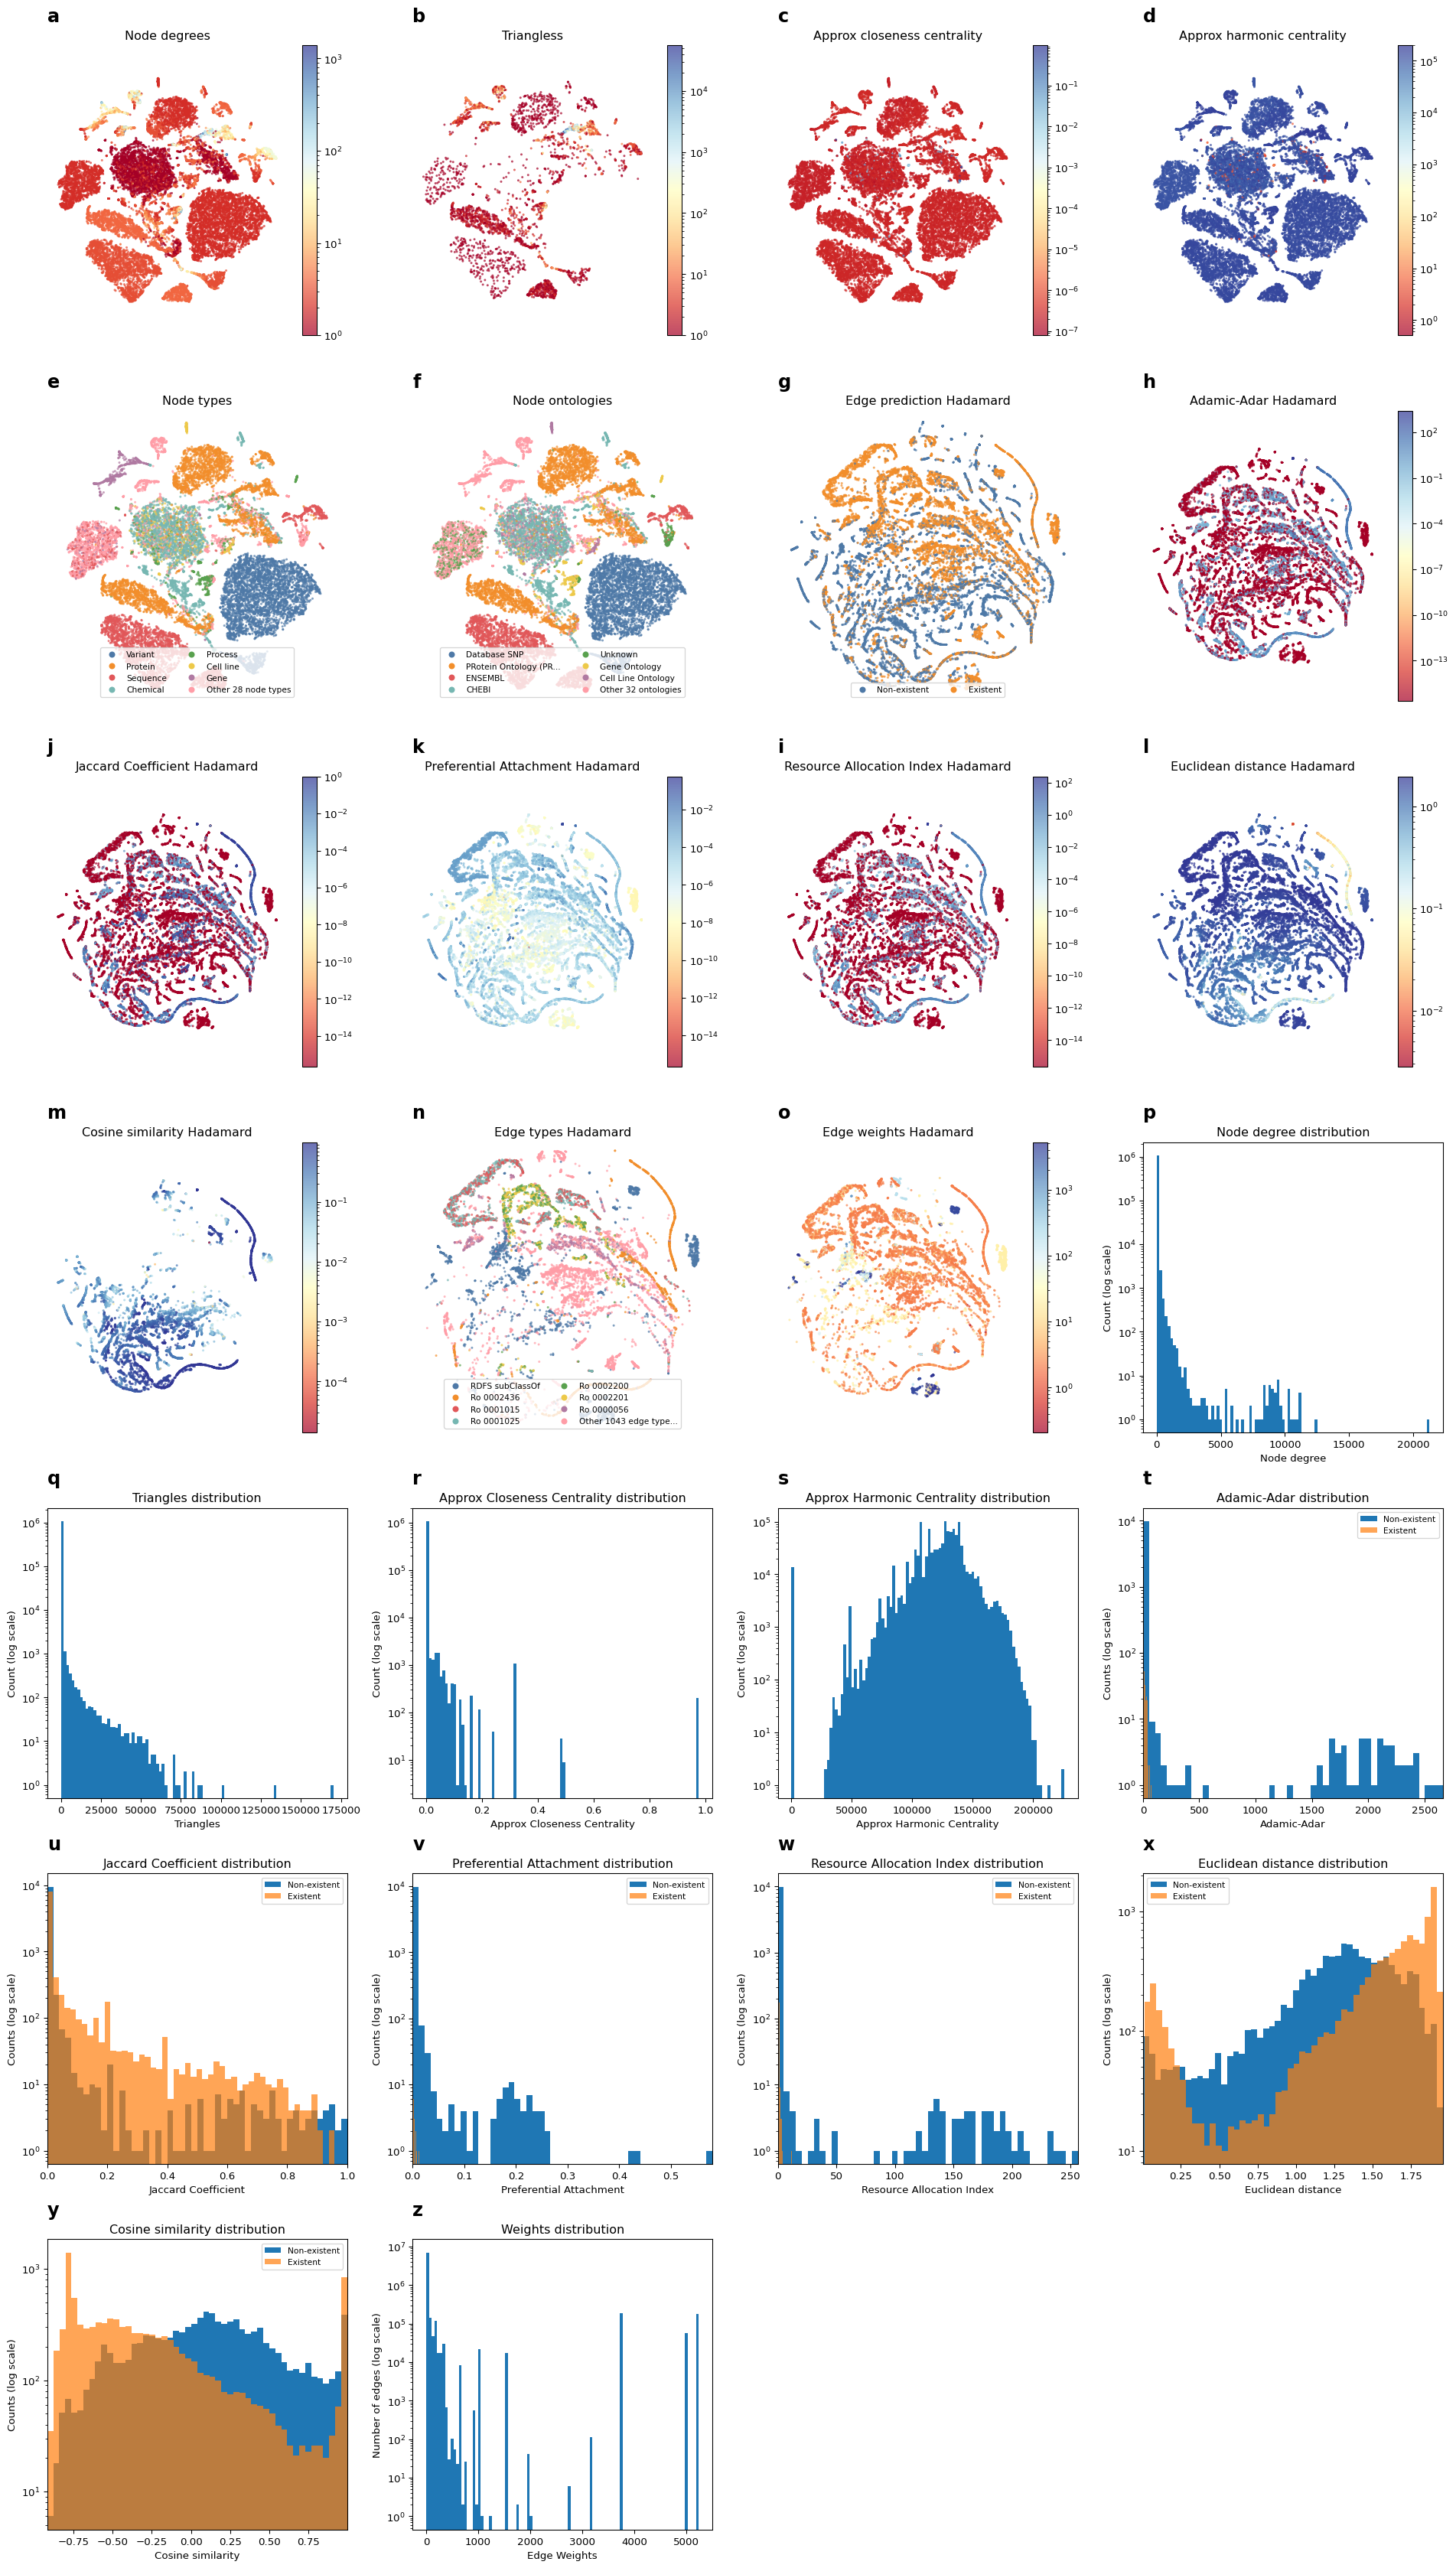

CPU times: user 9min 38s, sys: 11.7 s, total: 9min 50s
Wall time: 1min 26s


In [25]:
%%time
fig = vis_had.fit_and_plot_all(transe_embedding_hashed)

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 20000 samples in 0.001s...
[t-SNE] Computed neighbors for 20000 samples in 0.441s...
[t-SNE] Computed conditional probabilities for sample 1000 / 20000
[t-SNE] Computed conditional probabilities for sample 2000 / 20000
[t-SNE] Computed conditional probabilities for sample 3000 / 20000
[t-SNE] Computed conditional probabilities for sample 4000 / 20000
[t-SNE] Computed conditional probabilities for sample 5000 / 20000
[t-SNE] Computed conditional probabilities for sample 6000 / 20000
[t-SNE] Computed conditional probabilities for sample 7000 / 20000
[t-SNE] Computed conditional probabilities for sample 8000 / 20000
[t-SNE] Computed conditional probabilities for sample 9000 / 20000
[t-SNE] Computed conditional probabilities for sample 10000 / 20000
[t-SNE] Computed conditional probabilities for sample 11000 / 20000
[t-SNE] Computed conditional probabilities for sample 12000 / 20000
[t-SNE] Computed conditional probabilities for sam

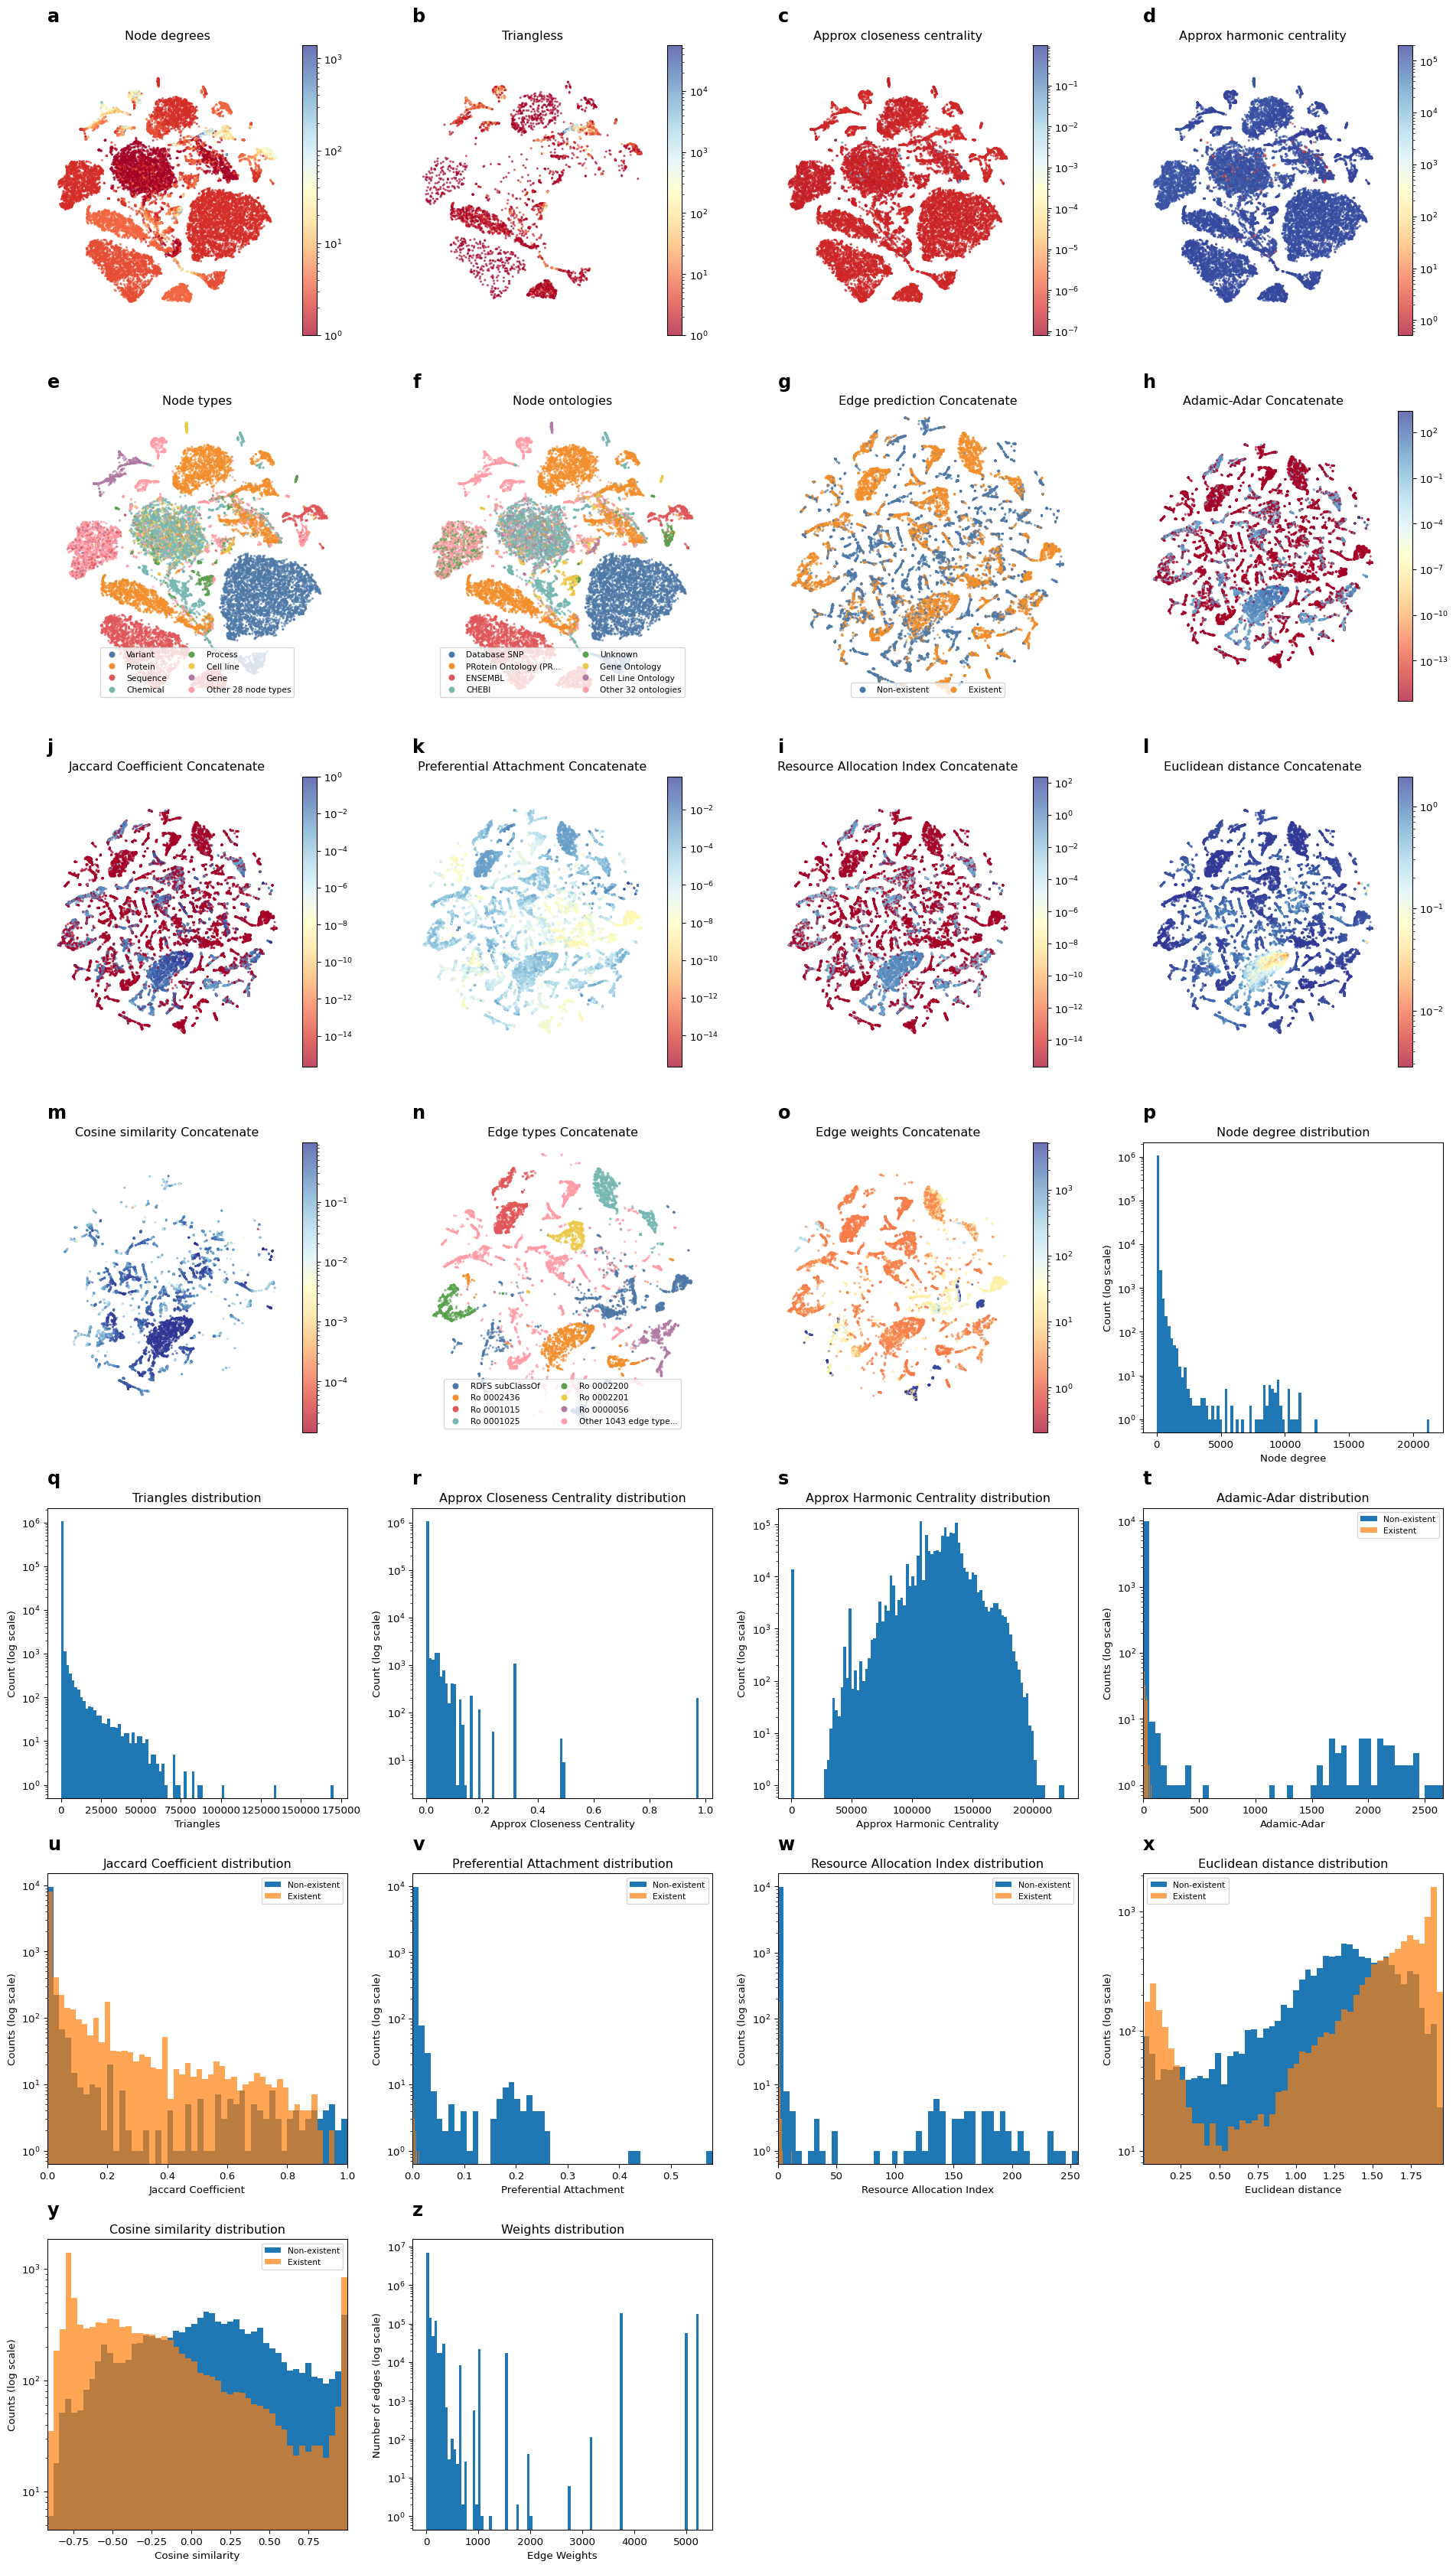

CPU times: user 8min 34s, sys: 12.6 s, total: 8min 47s
Wall time: 1min 14s


In [26]:
%%time
vis_conc = GraphVisualizer(npkg_hashed, verbose=True, edge_embedding_methods="Concatenate", rotate=False)
vis_conc.fit_and_plot_all(transe_embedding_hashed)

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 20000 samples in 0.001s...
[t-SNE] Computed neighbors for 20000 samples in 0.452s...
[t-SNE] Computed conditional probabilities for sample 1000 / 20000
[t-SNE] Computed conditional probabilities for sample 2000 / 20000
[t-SNE] Computed conditional probabilities for sample 3000 / 20000
[t-SNE] Computed conditional probabilities for sample 4000 / 20000
[t-SNE] Computed conditional probabilities for sample 5000 / 20000
[t-SNE] Computed conditional probabilities for sample 6000 / 20000
[t-SNE] Computed conditional probabilities for sample 7000 / 20000
[t-SNE] Computed conditional probabilities for sample 8000 / 20000
[t-SNE] Computed conditional probabilities for sample 9000 / 20000
[t-SNE] Computed conditional probabilities for sample 10000 / 20000
[t-SNE] Computed conditional probabilities for sample 11000 / 20000
[t-SNE] Computed conditional probabilities for sample 12000 / 20000
[t-SNE] Computed conditional probabilities for sam

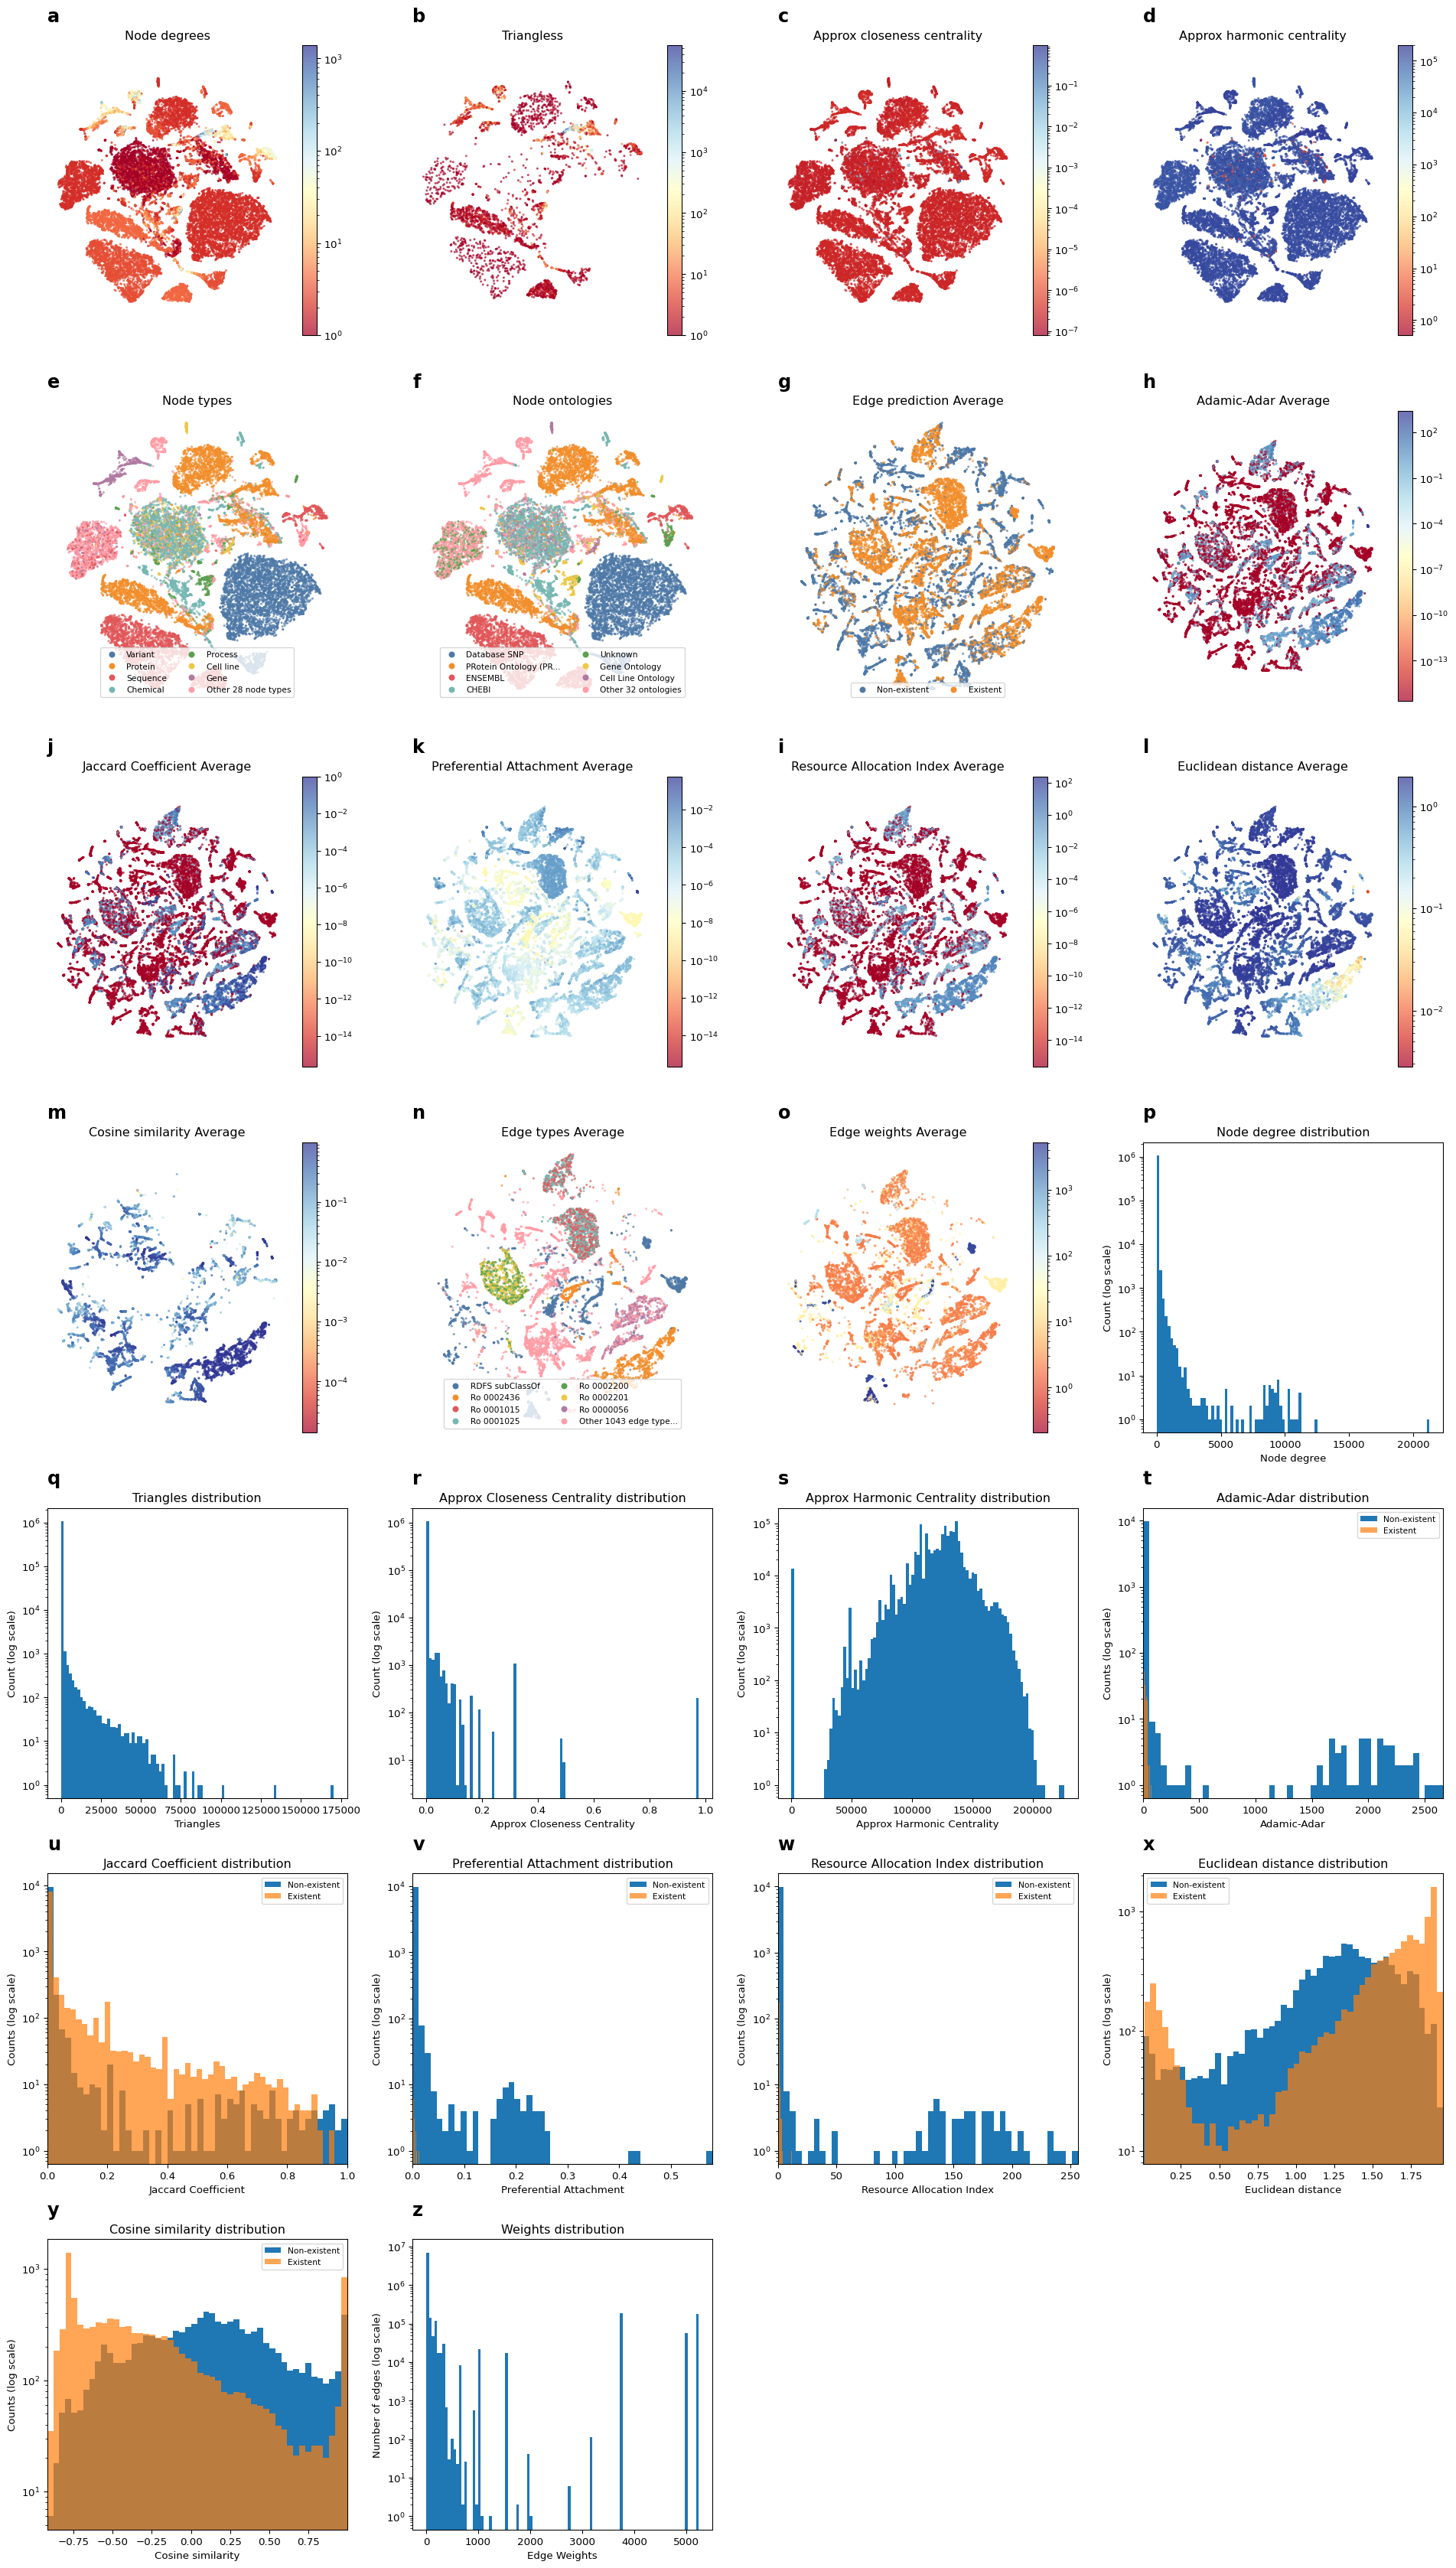

CPU times: user 9min 36s, sys: 11.3 s, total: 9min 47s
Wall time: 1min 20s


In [27]:
%%time
vis_mean = GraphVisualizer(npkg_hashed, verbose=True, edge_embedding_methods="Average", rotate=False)
vis_mean.fit_and_plot_all(transe_embedding_hashed)

### Visualize test embeddings for edge prediction (aggregation methods)

In [28]:
vis_test = GraphVisualizer(
    graph=test_hashed,
    support=npkg_hashed,
    edge_embedding_methods="Hadamard",
    verbose=True,
    decomposition_kwargs=dict(metric="euclidean"),
    automatically_display_on_notebooks=False
)

In [29]:
%%time
vis_test.fit_negative_and_positive_edges(transe_embedding_hashed)

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 20000 samples in 0.001s...
[t-SNE] Computed neighbors for 20000 samples in 0.397s...
[t-SNE] Computed conditional probabilities for sample 1000 / 20000
[t-SNE] Computed conditional probabilities for sample 2000 / 20000
[t-SNE] Computed conditional probabilities for sample 3000 / 20000
[t-SNE] Computed conditional probabilities for sample 4000 / 20000
[t-SNE] Computed conditional probabilities for sample 5000 / 20000
[t-SNE] Computed conditional probabilities for sample 6000 / 20000
[t-SNE] Computed conditional probabilities for sample 7000 / 20000
[t-SNE] Computed conditional probabilities for sample 8000 / 20000
[t-SNE] Computed conditional probabilities for sample 9000 / 20000
[t-SNE] Computed conditional probabilities for sample 10000 / 20000
[t-SNE] Computed conditional probabilities for sample 11000 / 20000
[t-SNE] Computed conditional probabilities for sample 12000 / 20000
[t-SNE] Computed conditional probabilities for sam

In [30]:
import matplotlib.pyplot as plt

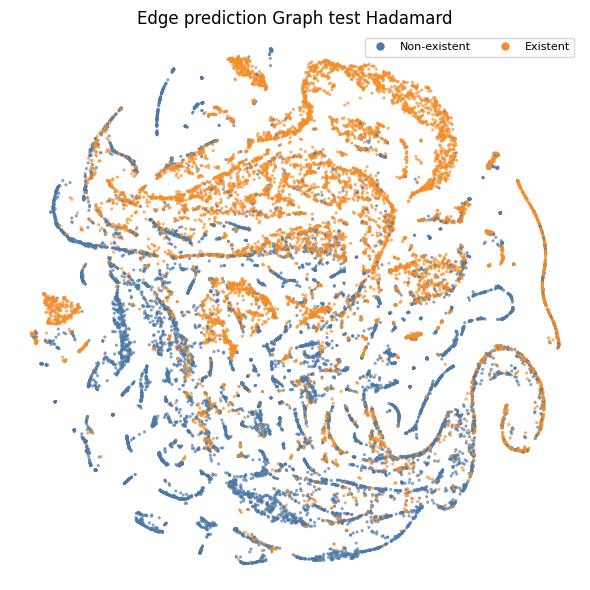

In [31]:
fig, ax = plt.subplots(figsize=(6,6))
vis_test.plot_positive_and_negative_edges(figure=fig, axes=ax)
fig.savefig('images/npkg_transe_test_edges_hashed.png')
plt.show()

In [32]:
plt.close(fig)

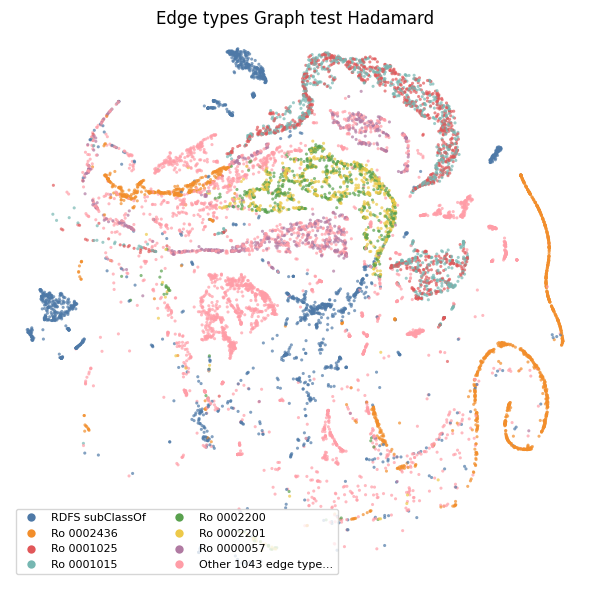

CPU times: user 837 ms, sys: 349 ms, total: 1.19 s
Wall time: 853 ms


In [33]:
%%time
fig, ax = plt.subplots(figsize=(6,6))
vis_test.plot_edge_types(figure=fig, axes=ax)
fig.savefig('images/npkg_transe_test_edge_types_hashed.png')
plt.show()

### Aggregate embeddings - only for multigraph

In [ ]:
aggregate_options = ['sum', 'concatenate', 'average', 'hadamard']

## Instrinsic evaluation of embeddings

See https://github.com/AnacletoLAB/grape/blob/main/tutorials/Graph_holdouts_using_GRAPE.ipynb

In [ ]:
hyperparameters_dict = {
    'learning_rate',
    'embedding_size',
    ''
}

In [18]:
trainc, testc = npkg.connected_holdout(
    train_size = 0.8,
    random_state=42,
    include_all_edge_types=True,
    #edge_types = [optional list of strings if restricting holdout/evaluation to specific edge types]
    verbose=True
)

In [13]:
print('Train holdout:')
print('Number of edges: ', train.get_number_of_edges())
print('Number of nodes: ', train.get_number_of_nodes())
print('Edge types: ', train.get_number_of_edge_types())

Train holdout:
Number of edges:  6538086
Number of nodes:  1090172
Edge types:  355


In [20]:
trainc.get_number_of_connected_components()

(1, 1090172, 1090172)

In [21]:
print('Test holdout:')
print('Number of edges: ', testc.get_number_of_edges())
print('Number of nodes: ', testc.get_number_of_nodes())
print('Edge types: ', testc.get_number_of_edge_types())

Test holdout:
Number of edges:  1584516
Number of nodes:  1090172
Edge types:  355


In [22]:
testc.get_number_of_connected_components()

(626641, 1, 435231)

In [23]:
##use the split for edge prediction to evaluate embeddings performance on existing graph
train_embedding = TransEEnsmallen(
    embedding_size=100,
    epochs=100,
    random_state=42,
    verbose=True,
    enable_cache=True
).fit_transform(trainc)

In [26]:
##save train embeddings
train_embedding_dict = train_embedding.dump()
with open(DIR_PATH+'npkg_train_transE_embedding_default.pickle', 'wb') as file_trans:
    pickle.dump(train_embedding_dict, file_trans)

In [25]:
train_embedding.get_node_embedding_from_index(0)

,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
ensembl:ENST00000669649,-0.103248,-0.085977,0.089353,0.177613,0.037632,0.159472,-0.111071,-0.082177,0.266919,0.076917,...,-0.020731,-0.081820,0.061503,-0.075545,-0.057711,0.080234,0.077626,0.077148,0.119082,0.081933
so:0000673,0.064789,-0.127085,-0.129978,-0.101585,0.069902,-0.047553,0.056269,-0.124169,0.200738,-0.090599,...,-0.052023,0.089451,0.075076,0.086892,-0.097427,0.118062,0.101841,-0.088904,-0.059074,0.161641
uberon:0006566,0.064531,0.067918,-0.094490,-0.054332,-0.112601,-0.059591,0.063965,0.068187,-0.531928,-0.092943,...,0.141300,0.098536,-0.118117,0.086771,0.101183,-0.070160,-0.080870,-0.099617,-0.063273,-0.087574
ensembl:ENST00000516725,-0.100111,-0.100013,0.072840,0.151695,0.052349,0.165647,-0.099397,-0.100291,0.200580,0.071543,...,-0.033058,-0.068572,0.063963,-0.073335,-0.070301,0.096429,0.079847,0.068141,0.117924,0.105745
ensembl:ENST00000645023,-0.099863,-0.102287,0.074181,0.151006,0.056224,0.164916,-0.102697,-0.098887,0.215996,0.068748,...,-0.035269,-0.066806,0.064201,-0.069916,-0.069725,0.095203,0.077302,0.069183,0.111854,0.110759
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
pr:p43506,0.084329,-0.079746,-0.114016,-0.064636,0.003434,0.028820,0.082955,-0.068570,0.465392,-0.135915,...,0.009755,0.222954,0.089392,0.076388,-0.054058,0.059962,0.085016,-0.131085,-0.004365,0.114058
pr:p57137,0.093253,-0.086024,-0.070469,-0.063845,0.115537,-0.126161,0.085874,-0.112256,0.106067,-0.095847,...,-0.144130,0.096692,0.090632,0.087126,-0.102246,0.076582,0.117531,-0.093602,-0.120207,0.138641
pr:m1wcq3,0.082039,-0.126933,-0.097077,-0.013327,0.084116,-0.013363,0.106453,-0.137368,0.037166,-0.125447,...,-0.071255,0.144801,0.127672,0.095309,-0.120116,0.122101,0.127666,-0.145285,-0.040069,0.103558
pr:p40755,0.031682,-0.135907,-0.049688,-0.098303,0.108422,-0.068153,0.040083,-0.123934,0.050488,-0.069326,...,-0.074885,0.053802,0.068013,0.065563,-0.095630,0.136609,0.116678,-0.066041,-0.069700,0.148350


In [27]:
train_embedding.get_edge_type_embedding_from_index(0)

,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
http://www.w3.org/2000/01/rdf-schema#subclassof,5.349654,-4.947885,-4.954153,-3.867646,5.084075,-3.884929,5.018682,-5.014336,0.532738,-5.290726,...,-4.984808,4.938831,4.639962,5.459168,-4.767118,5.208475,5.354243,-4.828157,-4.944083,4.241560
ro:0001015,-7.681180,-5.835968,7.251329,7.288846,7.302859,8.396789,-7.838548,-5.850613,1.740265,7.670742,...,-6.293336,-7.689614,7.153930,-7.704328,-5.046723,7.048419,7.946879,7.759255,9.272469,5.657763
ro:0001025,6.699061,6.471525,-6.603602,-5.678963,-7.878467,-6.876295,6.578207,6.393139,-1.657547,-7.363572,...,7.450162,7.081746,-8.881435,7.381374,5.892837,-7.978045,-9.265555,-7.049088,-9.136583,-6.182840
ro:0002150,0.372665,0.518920,0.821906,-0.511585,-1.223429,1.046381,0.460041,-0.108219,-0.884521,1.118075,...,0.612421,-0.744052,-0.886825,-0.047981,0.895510,-0.114980,-0.193459,-0.372875,0.226697,-0.324481
bfo:0000050,3.694185,4.223377,3.057095,-3.262762,-4.187925,-2.960180,3.911609,4.308225,-1.002170,3.348274,...,3.164570,-3.283582,-2.951803,-3.360641,3.315263,-4.404847,-4.448388,3.278879,3.389383,-3.567323
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ro:0002509,-0.138826,-0.195151,-0.321300,0.169943,0.029797,-0.248709,0.130700,0.100812,-0.122942,-0.247707,...,-0.090277,-0.013691,-0.116929,0.271797,-0.269291,0.120207,0.051918,-0.241381,-0.256571,0.100508
ncit:r81,-0.194552,-0.274963,-0.193647,0.005467,-0.113348,-0.241416,0.054725,0.064861,0.161184,0.196083,...,0.155734,-0.218340,-0.136067,-0.096399,-0.239356,-0.191587,0.015142,0.012475,0.116949,0.168975
so#transcribed:from,0.077021,0.129312,-0.208289,0.170166,-0.280710,0.109275,-0.196502,0.100493,0.395990,-0.107245,...,-0.028443,0.106425,0.074932,0.223901,-0.023728,0.121714,0.026975,0.182348,-0.155507,0.119589
foodon:00001301,-0.122838,-0.055280,-0.120337,-0.080357,-0.224572,0.021345,0.163888,-0.190505,0.111618,-0.175303,...,-0.246217,0.179261,-0.213111,-0.002047,0.111072,-0.169402,0.308831,-0.226298,0.151389,-0.194428


In [29]:
from grape.edge_prediction import MLPEdgePrediction, LogisticRegressionCVEdgePrediction

In [31]:
model1 = MLPEdgePrediction(
    edge_embedding_methods = "Hadamard"
)

model2 = LogisticRegressionCVEdgePrediction(
    edge_embedding_methods = "Hadamard"
)

In [35]:
model1.fit(
    graph = trainc,
    node_features = train_embedding.get_node_embedding_from_index(0),
    edge_type_features = train_embedding.get_edge_type_embedding_from_index(0),
    #edge_features
)

RuntimeError: An exception was raised while calling the `_fit` method of MLP Classifier implemented using the scikit-learn for the Edge Prediction task. Specifically, the class of the model is MLPClassifier.

In [38]:
model2.fit(
    graph = trainc,
    node_features = train_embedding.get_all_node_embedding(),
    node_type_features = None,
    edge_type_features = train_embedding.get_all_edge_type_embeddings(),
    #edge_features
)

RuntimeError: An exception was raised while calling the `_fit` method of Logistic Regression Cross Validator implemented using the scikit-learn for the Edge Prediction task. Specifically, the class of the model is LogisticRegressionCV.

In [ ]:
model.dump(path='json or pkl')

In [ ]:
%%time
# A perfect model should correctly predict the existance
# of all of these edges.
model.predict_proba(
    graph=test,
    node_features=train_embedding.get_node_embedding_from_index,
    return_predictions_dataframe=True
)

In [ ]:
%%time
# A perfect model should correctly predict the non-existance
# of all of these edges.
model.predict_proba(
    graph=graph.sample_negative_graph(number_of_negative_samples=test.get_number_of_edges()),
    node_features=train_embedding.get_node_embedding_from_index,
    return_predictions_dataframe=True
)

## k-fold train and test

In [ ]:
##to predict edge labels - maybe does not work with multigraph though
train, test = npkg.get_edge_label_kfold(
    k = 10,
    use_stratification = True,
    random_state = 42
)

In [ ]:
for i in range(0, 5):
    train, test = npkg.get_edge_prediction_kfold(
        k = 5,
        k_index = i,
        #edge_types = [optional list of strings if restricting holdout/evaluation to specific edge types]
        random_state=42,
        verbose=True
    )
    ##do training of embeddings with holdout
    ##test prediction on test graph and get metrics
    #metrics average over the folds